In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.utils.class_weight import compute_class_weight

In [2]:

# PATHS

ROOT_DIR = Path(r"C:\Btech\SEM5\cuda\DL\Frames_854_Stratified")

TRAIN_DIR = ROOT_DIR / "Training"
VAL_DIR   = ROOT_DIR / "Validation"
TEST_DIR  = ROOT_DIR / "Testing"


# CLASSES


CLASSES = [
    "Distraction",
    "Drinking",
    "Normal",
    "Phone",
    "Sleeping"
]

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASSES)
}

# TRAINING SETTINGS


SEED = 42

BATCH_SIZE = 16          
NUM_WORKERS = 0

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# REPRODUCIBILITY


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("Device :", DEVICE)

if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))



Device : cuda
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
def build_dataframe(split_path):

    data = []

    for class_name in CLASSES:

        class_folder = split_path / class_name

        if not class_folder.exists():
            continue

        for image_path in class_folder.iterdir():

            if image_path.suffix.lower() in IMAGE_EXTENSIONS:

                data.append({
                    "path": str(image_path),
                    "class": class_name,
                    "label": CLASS_TO_IDX[class_name]
                })

    return pd.DataFrame(data)


train_df = build_dataframe(TRAIN_DIR)
val_df   = build_dataframe(VAL_DIR)
test_df  = build_dataframe(TEST_DIR)

print("Training Images  :", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images   :", len(test_df))

Training Images  : 23026
Validation Images: 4935
Testing Images   : 4936


In [4]:
print("TRAINING")
display(train_df["class"].value_counts().sort_index())

print("\nVALIDATION")
display(val_df["class"].value_counts().sort_index())

print("\nTESTING")
display(test_df["class"].value_counts().sort_index())

TRAINING


class
Distraction    4370
Drinking       4913
Normal         4365
Phone          4937
Sleeping       4441
Name: count, dtype: int64


VALIDATION


class
Distraction     936
Drinking       1053
Normal          936
Phone          1058
Sleeping        952
Name: count, dtype: int64


TESTING


class
Distraction     937
Drinking       1053
Normal          936
Phone          1058
Sleeping        952
Name: count, dtype: int64

In [5]:
# IMAGE TRANSFORMS

train_transform = transforms.Compose([

    # Geometric Augmentation 
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=8),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),   # slight seat shift
        scale=(0.95, 1.05)
    ),

    #Lighting Augmentation
    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.15,
        hue=0.03
    ),

    # Slight blur to reduce identity memorization
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3)
    ], p=0.20),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation & Test
# No augmentation — only normalization

test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [6]:
class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(row["path"]).convert("RGB")

        image = self.transform(image)

        label = row["label"]

        return image, label


train_dataset = DriverDataset(train_df, train_transform)
val_dataset   = DriverDataset(val_df, test_transform)
test_dataset  = DriverDataset(test_df, test_transform)

In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# Class Weights (for imbalance)


weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df["label"]
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(DEVICE)

print("Class Weights")
for c, w in zip(CLASSES, weights):
    print(f"{c:15s}: {w:.3f}")

print("\nTrain Batches :", len(train_loader))
print("Val Batches   :", len(val_loader))
print("Test Batches  :", len(test_loader))

Class Weights
Distraction    : 1.054
Drinking       : 0.937
Normal         : 1.055
Phone          : 0.933
Sleeping       : 1.037

Train Batches : 1440
Val Batches   : 309
Test Batches  : 309


In [8]:
# CUSTOM CNN


class CustomCNN(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),


            # Block 2

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),


            # Block 3

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Dropout2d(0.20),


            # Block 4

            nn.Conv2d(
                128,
                256,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(256),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Dropout2d(0.20),


            # Block 5

            nn.Conv2d(
                256,
                512,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(512),

            nn.ReLU(inplace=True),

            nn.Dropout2d(0.20),


            # Global pooling

            nn.AdaptiveAvgPool2d((1, 1))
        )


        self.classifier = nn.Sequential(

            nn.Flatten(),


            # Fully connected layer

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(inplace=True),

            nn.Dropout(0.30),


            # Output layer

            nn.Linear(
                256,
                num_classes
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# CREATE MODEL


model = CustomCNN(
    len(CLASSES)
).to(DEVICE)


# COUNT TRAINABLE PARAMETERS


total_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad
)


print(model)

print(
    f"\nTrainable Parameters: {total_params:,}"
)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Dropout2d(p=0.2, inplace=False)
    (13): Conv2d(128, 256, kernel_size=(3, 3), stride=

In [9]:
# VERIFY SHAPES


images, labels = next(iter(train_loader))

print("Input Shape :", images.shape)

images = images.to(DEVICE)

outputs = model(images)

print("Output Shape:", outputs.shape)

Input Shape : torch.Size([16, 3, 480, 854])
Output Shape: torch.Size([16, 5])


In [10]:
# TRAINING CONFIGURATION

LEARNING_RATE = 1e-4
EPOCHS = 30


# Loss Function

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)


# Optimizer

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)


# Learning Rate Scheduler

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    threshold=1e-3,
    min_lr=1e-6
)


# Mixed Precision

scaler = torch.amp.GradScaler("cuda")


# Early Stopping

EARLY_STOPPING_PATIENCE = 10


print("Training Configuration")

print(f"Learning Rate : {LEARNING_RATE}")
print(f"Epochs        : {EPOCHS}")
print(f"Patience      : {EARLY_STOPPING_PATIENCE}")

Training Configuration
Learning Rate : 0.0001
Epochs        : 30
Patience      : 10


In [11]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm
import copy

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": []
}

best_f1 = 0
trigger = 0

best_model = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print("-"*50)

    model.train()

    train_loss = 0
    train_true = []
    train_pred = []

    for images, labels in tqdm(train_loader):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

        preds = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(preds.cpu().numpy())

    train_loss /= len(train_loader)

    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(train_true, train_pred, average="macro")

    model.eval()

    val_loss = 0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in tqdm(val_loader):

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            preds = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_loss /= len(val_loader)

    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(val_true, val_pred, average="macro")

    scheduler.step(val_f1)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    if val_f1 > best_f1:

        best_f1 = val_f1
        trigger = 0

        best_model = copy.deepcopy(model.state_dict())
        torch.save(best_model, "best_custom_cnn.pth")

        status = "Best Model Saved"

    else:

        trigger += 1
        status = f"EarlyStop {trigger}/{EARLY_STOPPING_PATIENCE}"

    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Acc : {train_acc:.4f} | "
        f"F1 : {train_f1:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f} | "
        f"Acc : {val_acc:.4f} | "
        f"F1 : {val_f1:.4f}"
    )

    print(status)

    if trigger >= EARLY_STOPPING_PATIENCE:

        print("\nEarly Stopping Triggered")
        break

print("\nTraining Completed")


Epoch [1/30]
--------------------------------------------------


100%|██████████| 309/309 [01:19<00:00,  3.90it/s]


Train Loss : 1.5822 | Acc : 0.2514 | F1 : 0.2485
Val Loss   : 1.5269 | Acc : 0.3248 | F1 : 0.2939
Best Model Saved

Epoch [2/30]
--------------------------------------------------


100%|██████████| 309/309 [01:22<00:00,  3.74it/s]


Train Loss : 1.5440 | Acc : 0.2933 | F1 : 0.2861
Val Loss   : 1.5254 | Acc : 0.2950 | F1 : 0.2377
EarlyStop 1/10

Epoch [3/30]
--------------------------------------------------


100%|██████████| 309/309 [01:02<00:00,  4.93it/s]


... (51 outputs left out)

100%|██████████| 309/309 [01:26<00:00,  3.58it/s]


Train Loss : 1.1749 | Acc : 0.5435 | F1 : 0.5417
Val Loss   : 0.9520 | Acc : 0.7191 | F1 : 0.7164
Best Model Saved

Epoch [30/30]
--------------------------------------------------


100%|██████████| 309/309 [01:25<00:00,  3.61it/s]

Train Loss : 1.1702 | Acc : 0.5476 | F1 : 0.5468
Val Loss   : 0.9492 | Acc : 0.6926 | F1 : 0.6865
EarlyStop 1/10

Training Completed


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# LOAD BEST MODEL


model.load_state_dict(
    torch.load(
        "best_custom_cnn.pth",
        map_location=DEVICE,
        weights_only=True
    )
)
model.eval()

test_predictions = []
test_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)

        preds = outputs.argmax(dim=1).cpu().numpy()

        test_predictions.extend(preds)
        test_labels.extend(labels.numpy())

print("Best model loaded successfully.")

Best model loaded successfully.


In [13]:
test_accuracy = accuracy_score(test_labels, test_predictions)

test_precision = precision_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

test_recall = recall_score(
    test_labels, test_predictions,
    average="macro", zero_division=0
)

test_f1 = f1_score(
    test_labels, test_predictions,
    average="macro"
)


print("FINAL TEST RESULTS")


print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"Macro F1  : {test_f1:.4f}")

print("\nCLASSIFICATION REPORT\n")

print(classification_report(
    test_labels,
    test_predictions,
    target_names=CLASSES,
    digits=4
))

cm = confusion_matrix(test_labels, test_predictions)

FINAL TEST RESULTS
Accuracy  : 0.7129
Precision : 0.7270
Recall    : 0.7112
Macro F1  : 0.7099

CLASSIFICATION REPORT

              precision    recall  f1-score   support

 Distraction     0.8511    0.8111    0.8306       937
    Drinking     0.7079    0.8424    0.7693      1053
      Normal     0.5761    0.7158    0.6384       936
       Phone     0.7062    0.6815    0.6936      1058
    Sleeping     0.7937    0.5053    0.6175       952

    accuracy                         0.7129      4936
   macro avg     0.7270    0.7112    0.7099      4936
weighted avg     0.7263    0.7129    0.7106      4936



In [14]:
#Create Results Folder

from pathlib import Path

RESULTS_DIR = Path("Training_Results")
RESULTS_DIR.mkdir(exist_ok=True)

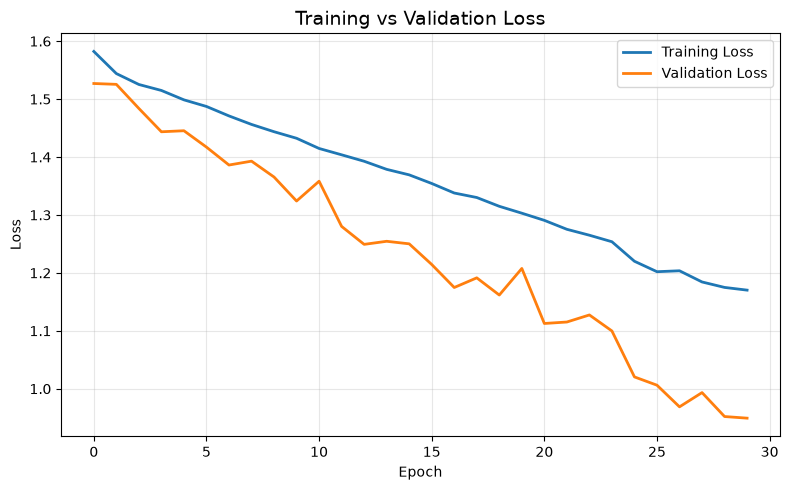

In [15]:
#Loss Curve

plt.figure(figsize=(8,5))

plt.plot(history["train_loss"], linewidth=2, label="Training Loss")
plt.plot(history["val_loss"], linewidth=2, label="Validation Loss")

plt.title("Training vs Validation Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=300)
plt.show()

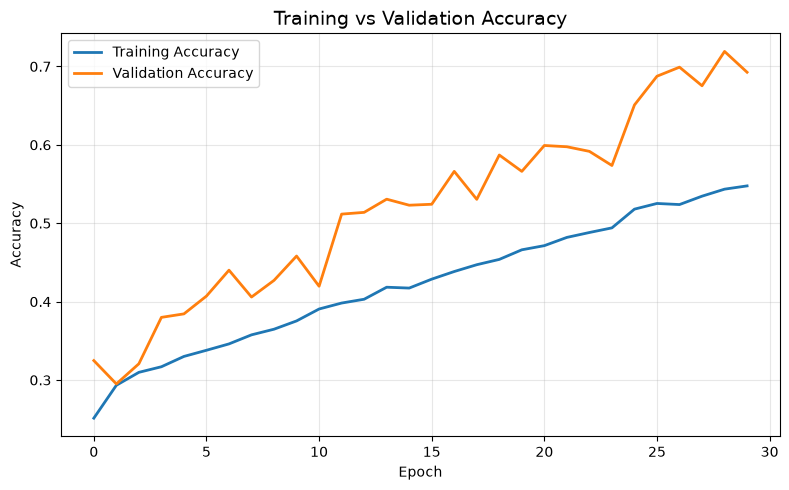

In [16]:
#Accuracy Curve

plt.figure(figsize=(8,5))

plt.plot(history["train_acc"], linewidth=2, label="Training Accuracy")
plt.plot(history["val_acc"], linewidth=2, label="Validation Accuracy")

plt.title("Training vs Validation Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_curve.png", dpi=300)
plt.show()

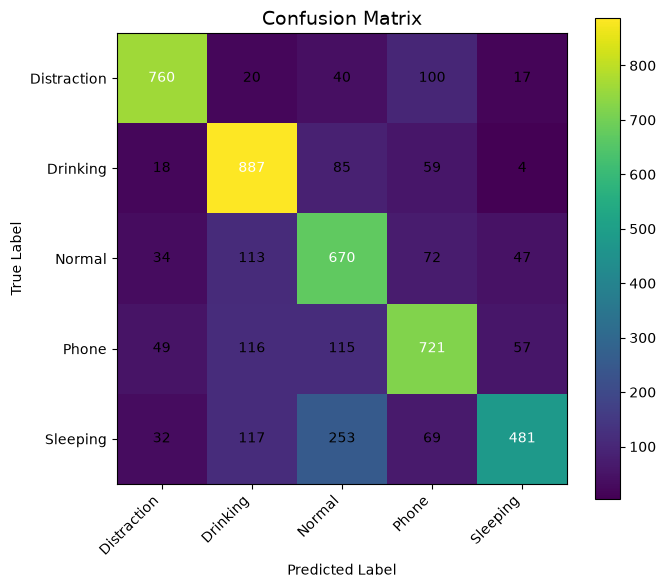

In [17]:
# Confusion Matrix

fig, ax = plt.subplots(figsize=(7,6))

im = ax.imshow(cm, interpolation="nearest")

ax.set_title("Confusion Matrix", fontsize=14)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))

ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticklabels(CLASSES)

# Write values inside cells
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.colorbar(im)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

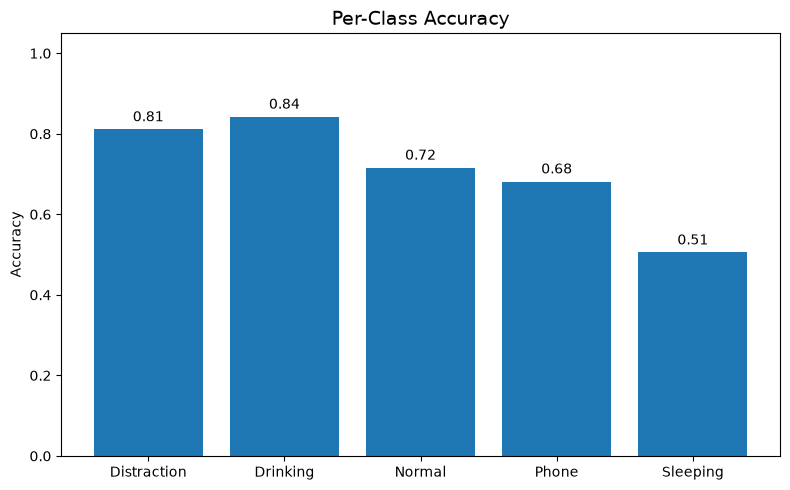

In [18]:
# Per-Class Accuracy
class_accuracy = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8,5))

plt.bar(CLASSES, class_accuracy)

plt.ylim(0,1.05)

plt.title("Per-Class Accuracy", fontsize=14)
plt.ylabel("Accuracy")

for i, value in enumerate(class_accuracy):

    plt.text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.savefig(RESULTS_DIR / "per_class_accuracy.png", dpi=300)
plt.show()

In [19]:
#Train summary

summary = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "Macro F1"
    ],
    "Value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(summary)

summary.to_csv(
    RESULTS_DIR / "test_metrics.csv",
    index=False
)

,Metric,Value
0,Test Accuracy,0.712925
1,Precision,0.726992
2,Recall,0.711199
3,Macro F1,0.709872
